# Data Analytics for Sustainability 
## Individual Assignment
## Electric Vehicle Population Data Analysis
## Name: Fareeha Nasir Khan
## Student ID: 567575

# Setup and Data Loading

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# Load Dataset
df = pd.read_csv('Electric_Vehicle_Population_Data.csv')

In [4]:
# Display Row and Column Information
print('Dataset Shape:')
print(df.shape)

Dataset Shape:
(112634, 17)


In [5]:
# Display Column Names:
print('\nColumn Names:')
print(df.columns.to_list())


Column Names:
['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Base MSRP', 'Legislative District', 'DOL Vehicle ID', 'Vehicle Location', 'Electric Utility', '2020 Census Tract']


In [6]:
# Display First Few Rows of Dataset
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,JTMEB3FV6N,Monroe,Key West,FL,33040,2022,TOYOTA,RAV4 PRIME,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,42,0,NaN,198968248,POINT (-81.80023 24.5545),NaN,12087972100
1,1G1RD6E45D,Clark,Laughlin,NV,89029,2013,CHEVROLET,VOLT,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,38,0,NaN,5204412,POINT (-114.57245 35.16815),NaN,32003005702
2,JN1AZ0CP8B,Yakima,Yakima,WA,98901,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73,0,15.0,218972519,POINT (-120.50721 46.60448),PACIFICORP,53077001602
3,1G1FW6S08H,Skagit,Concrete,WA,98237,2017,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,238,0,39.0,186750406,POINT (-121.7515 48.53892),PUGET SOUND ENERGY INC,53057951101
4,3FA6P0SU1K,Snohomish,Everett,WA,98201,2019,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26,0,38.0,2006714,POINT (-122.20596 47.97659),PUGET SOUND ENERGY INC,53061041500


# Data Understanding

In [7]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112634 entries, 0 to 112633
Data columns (total 17 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         112634 non-null  object 
 1   County                                             112634 non-null  object 
 2   City                                               112634 non-null  object 
 3   State                                              112634 non-null  object 
 4   Postal Code                                        112634 non-null  int64  
 5   Model Year                                         112634 non-null  int64  
 6   Make                                               112634 non-null  object 
 7   Model                                              112614 non-null  object 
 8   Electric Vehicle Type                              112634 non-null  object

In [8]:
# Statistical Summary of Dataset
df.describe()

,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,112634.000000,112634.000000,112634.000000,112634.000000,112348.000000,1.126340e+05,1.126340e+05
mean,98156.226850,2019.003365,87.812987,1793.439681,29.805604,1.994567e+08,5.296650e+10
std,2648.733064,2.892364,102.334216,10783.753486,14.700545,9.398427e+07,1.699104e+09
min,1730.000000,1997.000000,0.000000,0.000000,1.000000,4.777000e+03,1.101001e+09
25%,98052.000000,2017.000000,0.000000,0.000000,18.000000,1.484142e+08,5.303301e+10
50%,98119.000000,2020.000000,32.000000,0.000000,34.000000,1.923896e+08,5.303303e+10
75%,98370.000000,2022.000000,208.000000,0.000000,43.000000,2.191899e+08,5.305307e+10
max,99701.000000,2023.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.603300e+10


In [9]:
# Categorical Summary of Dataset
df.describe(include='object')

,VIN (1-10),County,City,State,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Vehicle Location,Electric Utility
count,112634,112634,112634,112634,112634,112614,112634,112634,112610,112191
unique,7548,165,629,45,34,114,2,3,758,73
top,5YJYGDEE9M,King,Seattle,WA,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,POINT (-122.13158 47.67858),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)
freq,472,59000,20305,112348,52078,23135,86044,58639,2916,40247


In [10]:
# Check Missing Values
df.isnull().sum()

VIN (1-10)                                             0
County                                                 0
City                                                   0
State                                                  0
Postal Code                                            0
Model Year                                             0
Make                                                   0
Model                                                 20
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         0
Base MSRP                                              0
Legislative District                                 286
DOL Vehicle ID                                         0
Vehicle Location                                      24
Electric Utility                                     443
2020 Census Tract                                      0
dtype: int64

In [11]:
# Check Duplicate Records in Dataset
print('Duplicate Rows:', df.duplicated().sum())

Duplicate Rows: 0


# Data Preprocessing and Cleaning

## Handling Missing Values

#### Missing values were identified in four columns: Model, Legislative District, Vehicle Location and Electric Utility. Imputation method was selected based on nature of each variable rather than applying a single technique to all columns. 
- Model is a categorical variable and was imputed using the mode (most frequent category).
- Electric Utility is a categorical variable and was imputed using the mode (most frequent category).
- Legislative District represents district identifiers and was imputed using the median value to avoid introducing non-representative values.
- Vehicle Location contains geographical coordinate information. Because geographic coordinates are highly specific and only 24 values were missing (approximately 0.02% of the dataset), these missing values were retained rather than imputed to avoid creating artificial location data.

In [12]:
# Impute Model using Mode
df['Model'] = df['Model'].fillna(df['Model'].mode()[0])

# Impute Electric Utility using Mode
df['Electric Utility'] = df['Electric Utility'].fillna(df['Electric Utility'].mode()[0])

# Impute Legislative District using Median
df['Legislative District'] = df['Legislative District'].fillna(df['Legislative District'].median())

#### After performing imputation of the missing values, the missing values of all the columns were re-evaluated to verify the effectiveness of preprocessing.

In [13]:
df.isnull().sum()

VIN (1-10)                                            0
County                                                0
City                                                  0
State                                                 0
Postal Code                                           0
Model Year                                            0
Make                                                  0
Model                                                 0
Electric Vehicle Type                                 0
Clean Alternative Fuel Vehicle (CAFV) Eligibility     0
Electric Range                                        0
Base MSRP                                             0
Legislative District                                  0
DOL Vehicle ID                                        0
Vehicle Location                                     24
Electric Utility                                      0
2020 Census Tract                                     0
dtype: int64

# Data Transformation

## Filtering

In [14]:
# Filter BEVs
bev_df = df[df['Electric Vehicle Type'] == 'Battery Electric Vehicle (BEV)']
print("Number of BEVs:")
print(bev_df.shape[0])

Number of BEVs:
86044


In [15]:
# Filter Tesla Vehicles
tesla_df = df[df['Make'] == 'TESLA']
print("Number of Tesla Vehicles:")
print(tesla_df.shape[0])

Number of Tesla Vehicles:
52078


## Sorting

In [16]:
# Top EVs by Electric Range
top_range = df.sort_values(by='Electric Range',ascending=False)
top_range[['Make','Model','Electric Range']].head(10)

,Make,Model,Electric Range
98005,TESLA,MODEL S,337
16433,TESLA,MODEL S,337
102293,TESLA,MODEL S,337
53153,TESLA,MODEL S,337
97322,TESLA,MODEL S,337
35550,TESLA,MODEL S,337
45541,TESLA,MODEL S,337
76683,TESLA,MODEL S,337
24485,TESLA,MODEL S,337
85944,TESLA,MODEL S,337


## Grouping

In [17]:
# Average Electric Range by Manufacturer
avg_range = (df.groupby('Make')['Electric Range'].mean().sort_values(ascending=False))
avg_range.head(10)

Make
JAGUAR            207.287671
TESLA             118.162756
CHEVROLET         109.766549
TH!NK             100.000000
NISSAN             89.326941
FIAT               85.624088
KIA                67.631943
AUDI               62.876930
SMART              62.282051
AZURE DYNAMICS     56.000000
Name: Electric Range, dtype: float64

In [18]:
# EV Counts by County
county_counts = (df.groupby('County').size().sort_values(ascending=False))
county_counts.head(10)

County
King         59000
Snohomish    12434
Pierce        8535
Clark         6689
Thurston      4126
Kitsap        3847
Whatcom       2840
Spokane       2792
Benton        1376
Island        1307
dtype: int64

In [19]:
# EV Type Counts
ev_type_counts = (df.groupby('Electric Vehicle Type').size().sort_values(ascending=False))
ev_type_counts

Electric Vehicle Type
Battery Electric Vehicle (BEV)            86044
Plug-in Hybrid Electric Vehicle (PHEV)    26590
dtype: int64

# Exploratory Data Analysis

## 1. Univariate Analysis

### Graph 1: Model Year Distribution

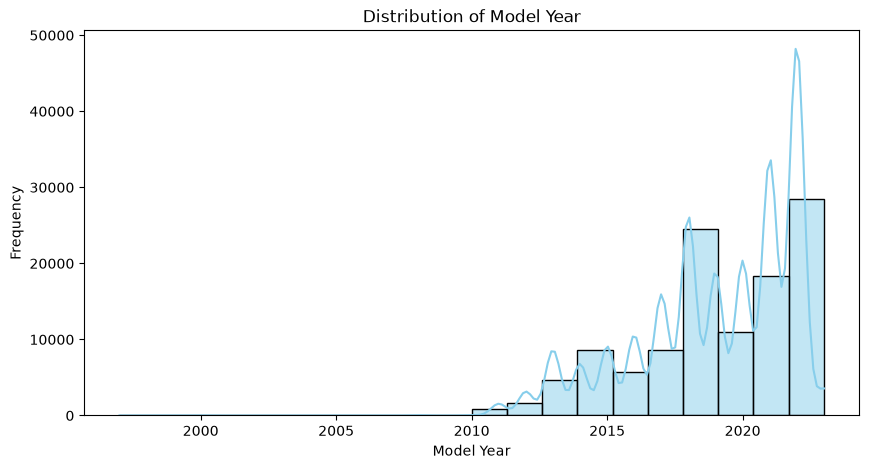

In [20]:
plt.figure(figsize=(10,5))
sns.histplot(data=df,x='Model Year',bins=20,kde=True,color='skyblue')
plt.title('Distribution of Model Year')
plt.xlabel('Model Year')
plt.ylabel('Frequency')
plt.show()

#### The distribution is heavily concentrated in recent years, particularly between 2018 and 2022, indicating a significant increase in electric vehicle registrations over time. Older model years have comparatively fewer vehicles, suggesting increased EV adoption in recent years.

### Graph 2: Electric Range Distribution

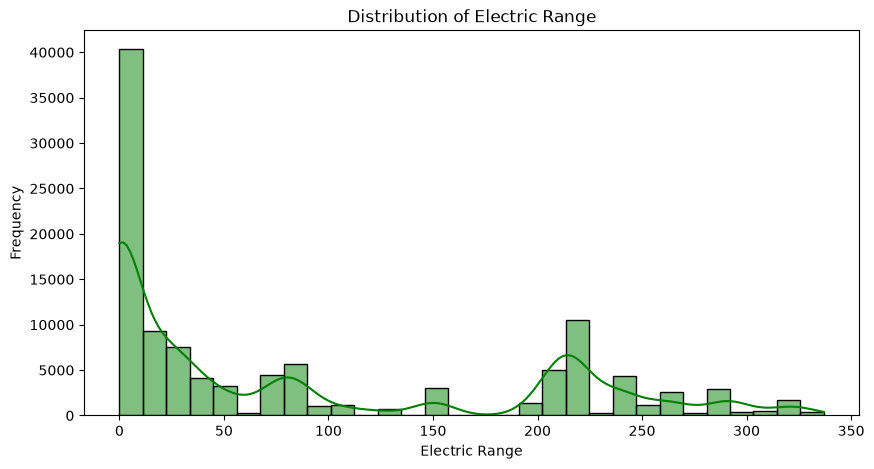

In [21]:
plt.figure(figsize=(10,5))
sns.histplot(data=df,x='Electric Range',bins=30,kde=True,color='green')
plt.title('Distribution of Electric Range')
plt.xlabel('Electric Range')
plt.ylabel('Frequency')
plt.show()

#### The electric range distribution is positively skewed with many vehicles having lower ranges and fewer vehicles achieving very high ranges. Multiple peaks suggest the presence of different EV segments.

### Graph 3: Legislative District Distribution

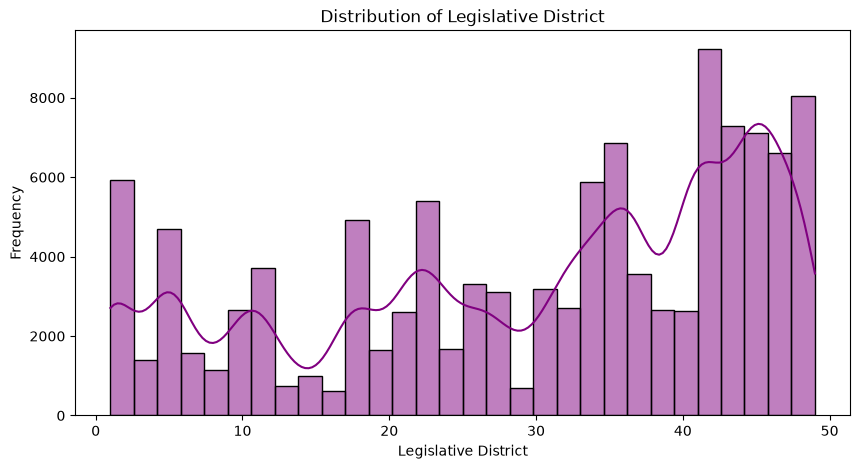

In [22]:
plt.figure(figsize=(10,5))
sns.histplot(df['Legislative District'],bins=30,kde=True,color='purple')
plt.title('Distribution of Legislative District')
plt.xlabel('Legislative District')
plt.ylabel('Frequency')
plt.show()

#### Electric vehicle registrations are distributed across multiple legislative districts, though some districts have noticeably higher concentrations than others. This indicates variations in EV adoption across geographic regions.

### Graph 4: Top 10 Vehicle Makes

C:\Users\Admin\AppData\Local\Temp\ipykernel_14008\2276853174.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_make.index,y=top_make.values,palette='viridis')


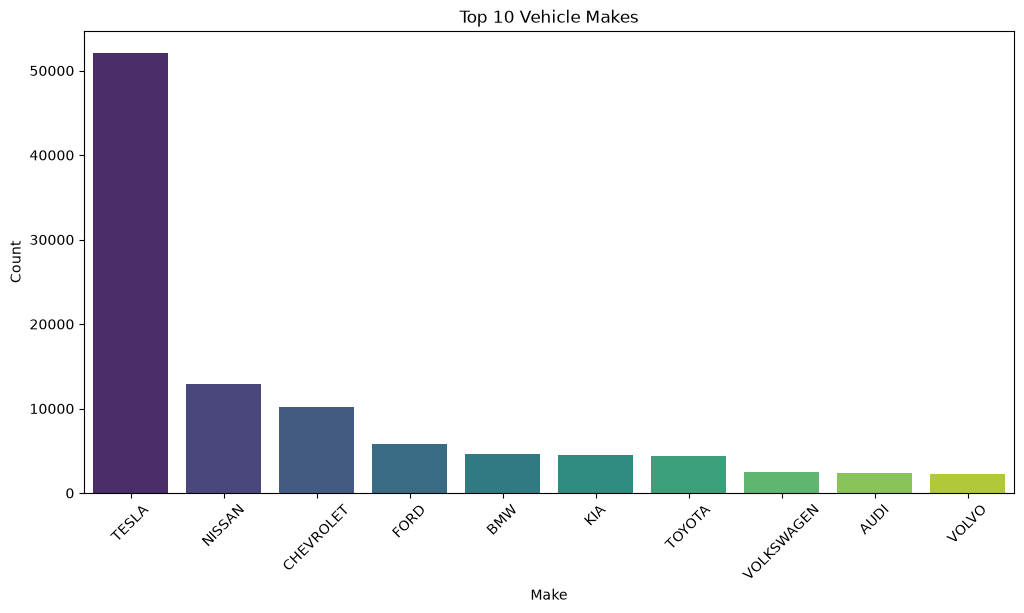

In [23]:
top_make = df['Make'].value_counts().head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=top_make.index,y=top_make.values,palette='viridis')
plt.title('Top 10 Vehicle Makes')
plt.xlabel('Make')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

#### Tesla dominates the dataset by a significant margin, indicating its strong market presence in the electric vehicle sector. Nissan and Chevrolet are the next most common manufacturers. Volvo is the least common manufacturer in the dataset.

### Graph 5: Top 10 Vehicle Models

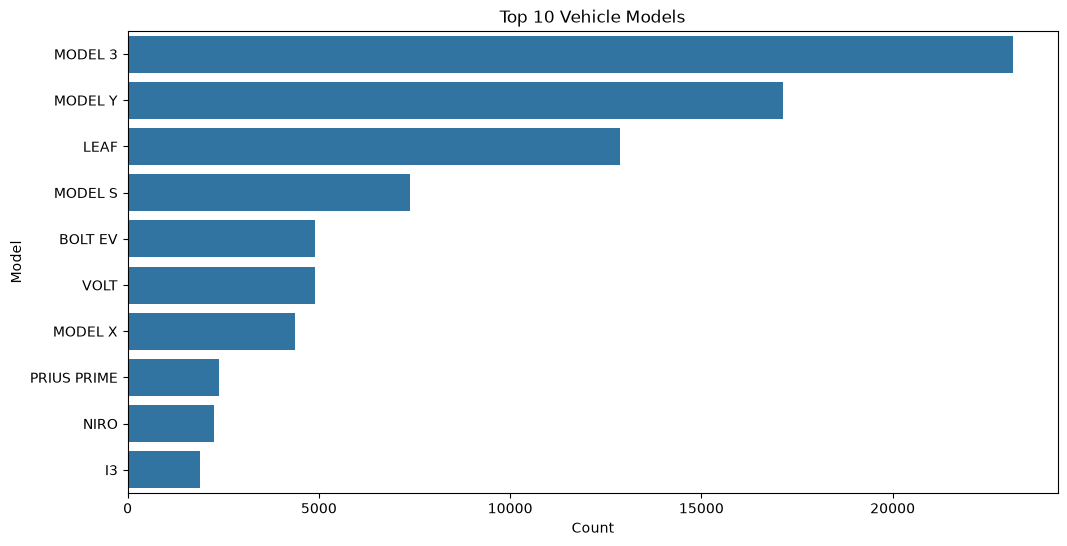

In [24]:
plt.figure(figsize=(12,6))
sns.countplot(y='Model',data=df,order=df['Model'].value_counts().head(10).index)
plt.title('Top 10 Vehicle Models')
plt.xlabel('Count')
plt.ylabel('Model')
plt.show()

#### Vehicle registrations are highly concentrated among a few dominant models, particularly Tesla Model 3, Tesla Model Y, and Nissan LEAF. This distribution suggests that a limited number of vehicle models account for a large share of overall EV adoption within the dataset.

### Graph 6: Electric Vehicle Type

C:\Users\Admin\AppData\Local\Temp\ipykernel_14008\3150304553.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='Electric Vehicle Type',palette='Set2')


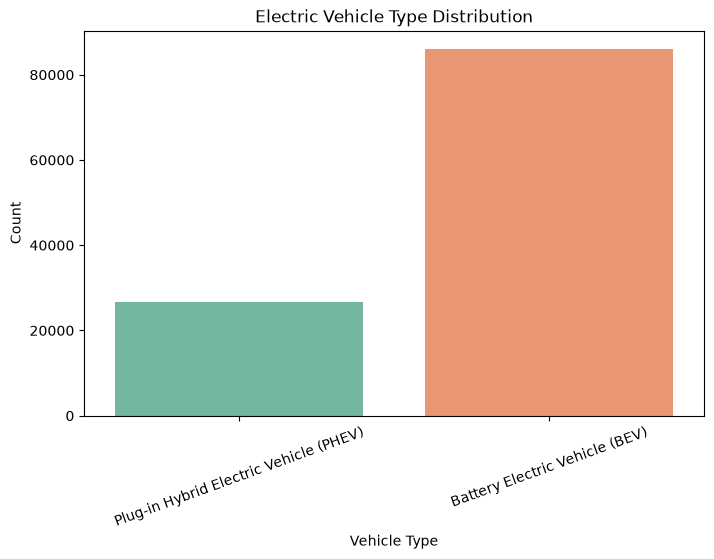

In [25]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='Electric Vehicle Type',palette='Set2')
plt.title('Electric Vehicle Type Distribution')
plt.xlabel('Vehicle Type')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()

#### Battery Electric Vehicles (BEVs) greatly outnumber Plug-in Hybrid Electric Vehicles (PHEVs), suggesting that fully electric vehicles are more widely adopted than hybrid electric vehicles in this dataset.

### Graph 7: CAFV Eligibility

C:\Users\Admin\AppData\Local\Temp\ipykernel_14008\2893953387.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,y='Clean Alternative Fuel Vehicle (CAFV) Eligibility',palette='coolwarm')


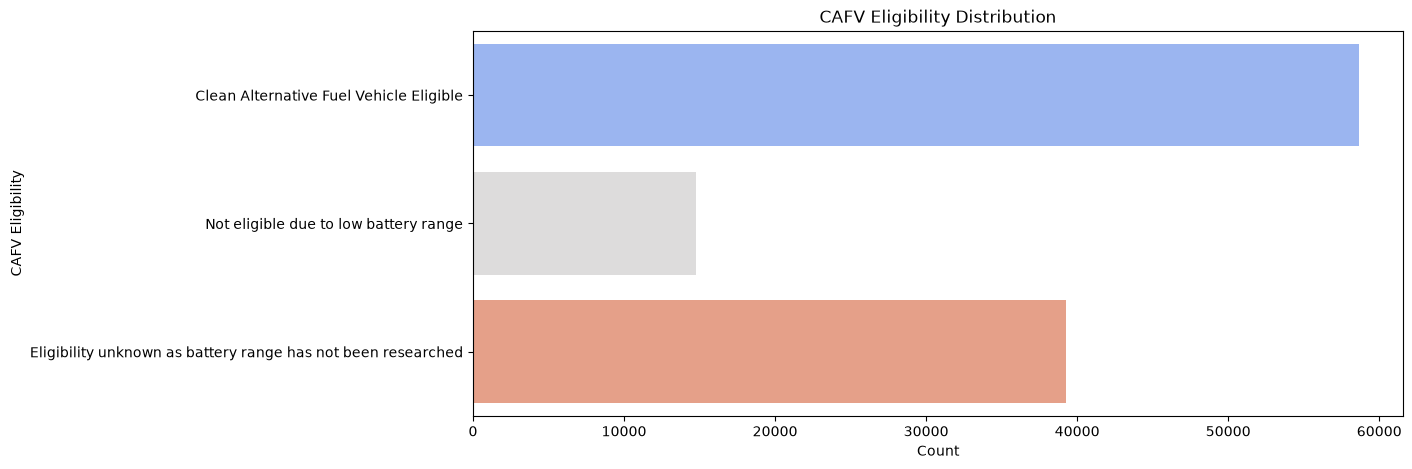

In [26]:
plt.figure(figsize=(12,5))
sns.countplot(data=df,y='Clean Alternative Fuel Vehicle (CAFV) Eligibility',palette='coolwarm')
plt.title('CAFV Eligibility Distribution')
plt.xlabel('Count')
plt.ylabel('CAFV Eligibility')
plt.show()

#### Most vehicles are classified as Clean Alternative Fuel Vehicle eligible, while a smaller proportion are either ineligible due to low battery range or have eligibility that has not yet been determined. This indicates broad compliance with clean fuel vehicle standards among registered EVs.

### Graph 8: Top 10 Counties

C:\Users\Admin\AppData\Local\Temp\ipykernel_14008\1177218833.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_counties.values,y=top_counties.index,palette='magma')


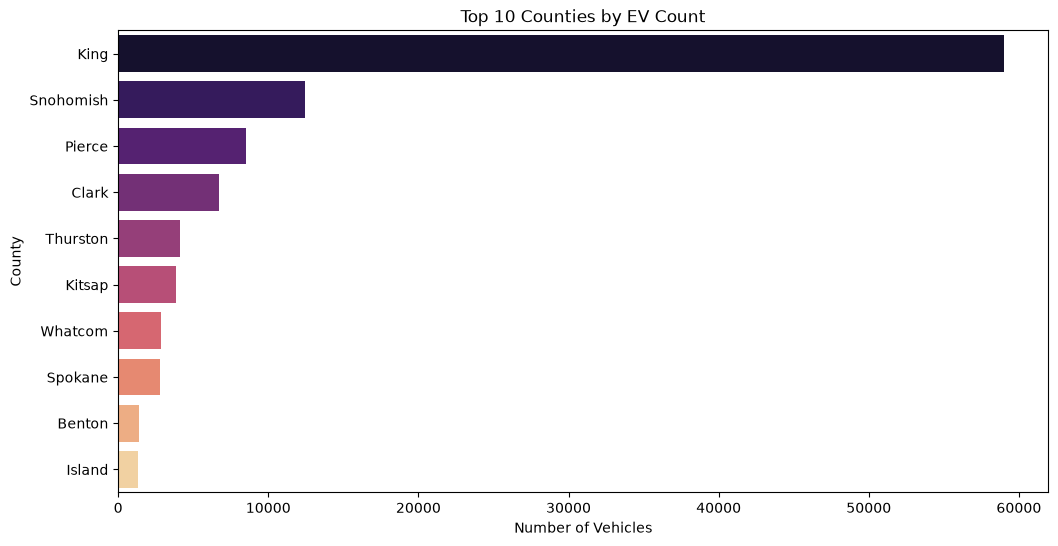

In [27]:
top_counties = df['County'].value_counts().head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=top_counties.values,y=top_counties.index,palette='magma')
plt.title('Top 10 Counties by EV Count')
plt.xlabel('Number of Vehicles')
plt.ylabel('County')
plt.show()

#### King County has by far the highest number of registered electric vehicles, significantly exceeding all other counties. This suggests that EV adoption is heavily concentrated in major urban and densely populated areas.

## 2. Outlier Analysis

### Boxplot 1: Model Year

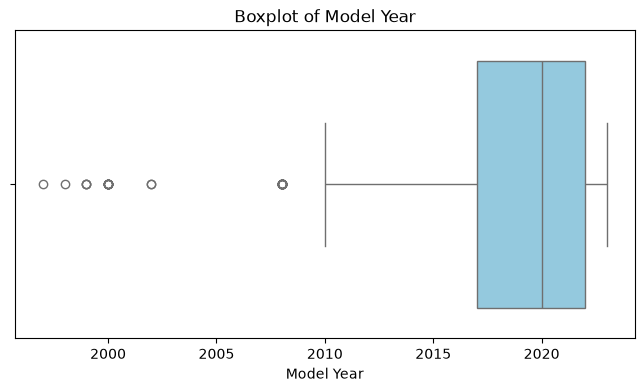

In [28]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Model Year'],color='skyblue')
plt.title('Boxplot of Model Year')
plt.show()

#### Most vehicles are concentrated between model years 2017 and 2022, with a median around 2020. A small number of older vehicles appear as outliers, indicating that the dataset is dominated by relatively newer EV models.

### Boxplot 2: Electric Range

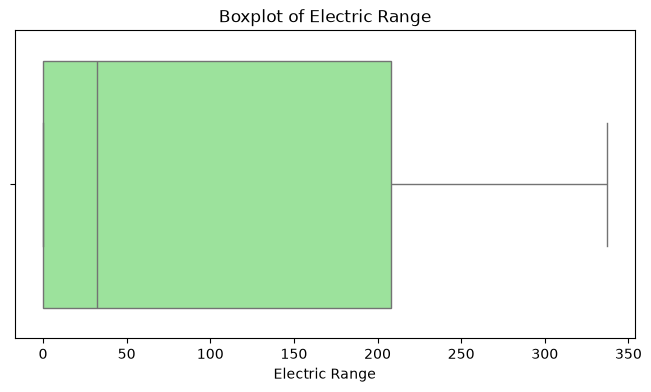

In [29]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Electric Range'],color='lightgreen')
plt.title('Boxplot of Electric Range')
plt.show()

#### Electric range values show substantial variability, with most vehicles exhibiting lower to moderate ranges and a smaller proportion achieving very high ranges. The wide spread indicates differences in battery technologies and vehicle types within the dataset.

### Boxplot 3: Postal Code

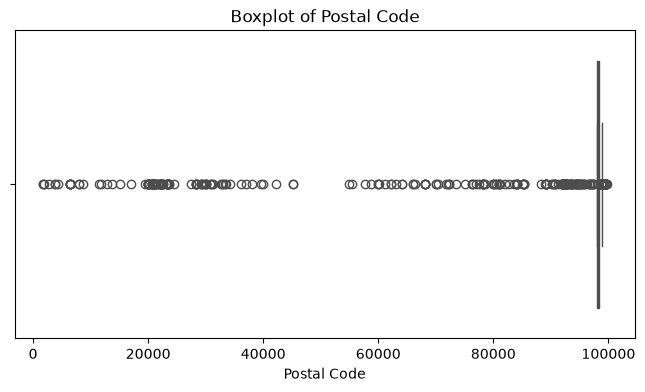

In [30]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Postal Code'], color='blue')
plt.title('Boxplot of Postal Code')
plt.show()

#### Most vehicle registrations are concentrated within a relatively narrow postal code range, while numerous points appear as outliers. These outliers likely represent vehicles registered across different geographic regions rather than erroneous observations.

### Boxplot 4: Legislative District

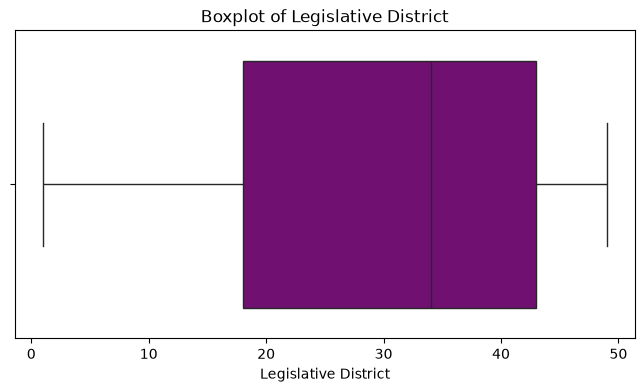

In [31]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Legislative District'],color='purple')
plt.title('Boxplot of Legislative District')
plt.show()

#### Vehicle registrations are spread across a wide range of legislative districts with the median district lying around the mid-30s. The absence of significant outliers suggests a relatively balanced distribution of EV registrations across districts.

### IQR Outlier Count

In [32]:
numerical_cols = ['Model Year','Electric Range','Base MSRP','Legislative District']
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col)
    print('Outliers:', len(outliers))
    print('Percentage:', round(len(outliers)/len(df)*100,2),'%')
    print()

Model Year
Outliers: 40
Percentage: 0.04 %

Electric Range
Outliers: 0
Percentage: 0.0 %

Base MSRP
Outliers: 3512
Percentage: 3.12 %

Legislative District
Outliers: 0
Percentage: 0.0 %



## 3. Bivariate Analysis

### Graph 1: Model Year vs Electric Range

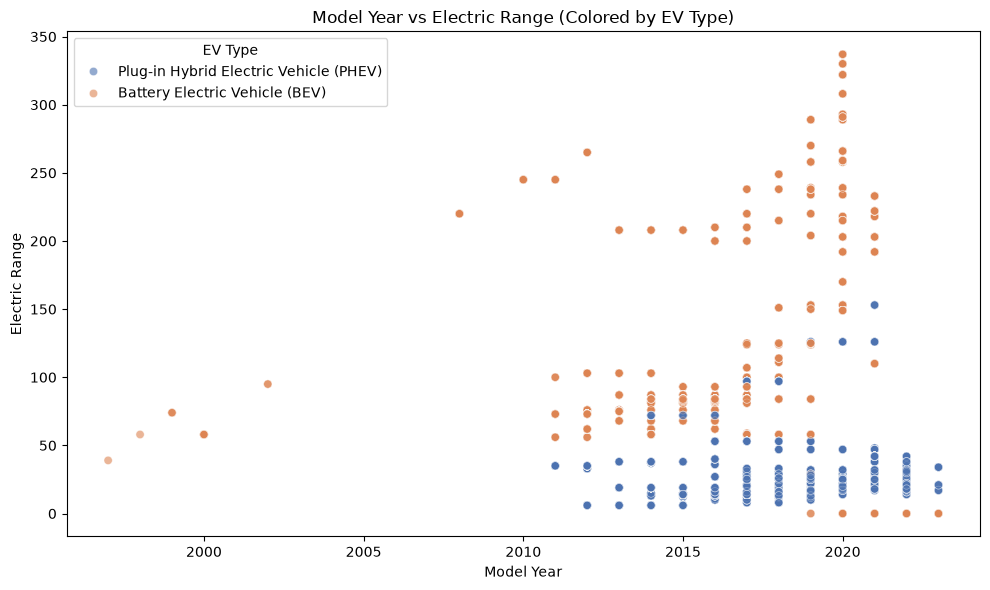

In [33]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,x='Model Year',y='Electric Range',hue='Electric Vehicle Type',palette='deep',alpha=0.6,)
plt.title('Model Year vs Electric Range (Colored by EV Type)')
plt.legend(title='EV Type', loc='best')
plt.tight_layout()
plt.show()

#### Battery Electric Vehicles (BEVs) generally exhibit higher electric ranges than Plug-in Hybrid Electric Vehicles (PHEVs) across most model years. Newer vehicles tend to achieve greater driving ranges, indicating advancements in EV battery technology over time.

### Graph 2: Model Year vs Legislative District

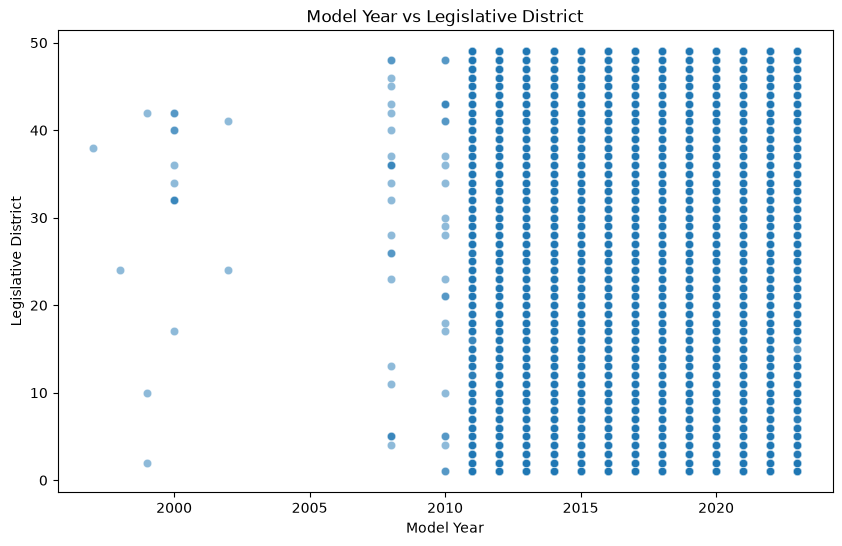

In [34]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='Model Year',y='Legislative District',alpha=0.5)
plt.title('Model Year vs Legislative District')
plt.show()

#### Electric vehicle registrations are observed across nearly all legislative districts with newer model years appearing consistently throughout the districts. This suggests that EV adoption is geographically widespread rather than concentrated in only a few legislative areas.

### Graph 3: EV Type vs Electric Range

C:\Users\Admin\AppData\Local\Temp\ipykernel_14008\1144060767.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Electric Vehicle Type',y='Electric Range',palette='deep')
C:\Users\Admin\AppData\Local\Temp\ipykernel_14008\1144060767.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='EV Type', loc='best')


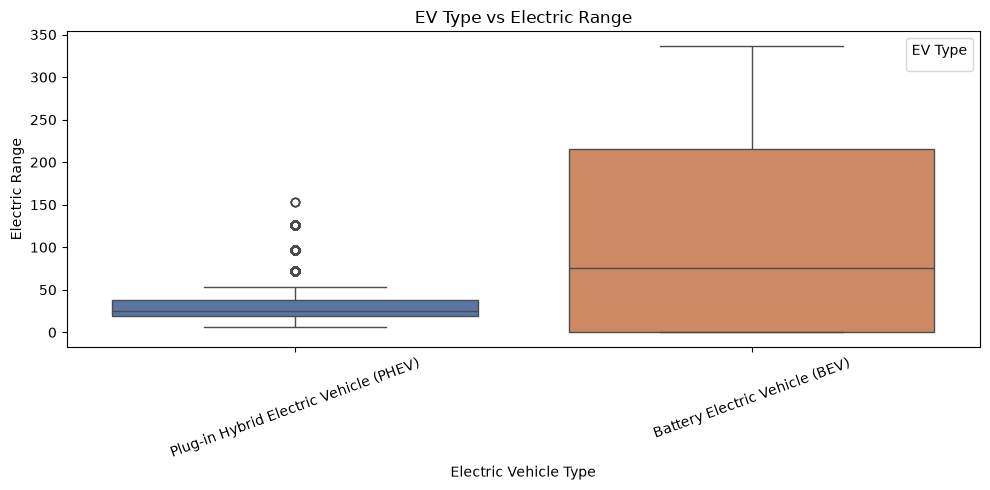

In [35]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x='Electric Vehicle Type',y='Electric Range',palette='deep')
plt.xticks(rotation=20)
plt.title('EV Type vs Electric Range')
plt.legend(title='EV Type', loc='best')
plt.tight_layout()
plt.show()

#### Battery Electric Vehicles (BEVs) have substantially higher electric ranges and greater variability compared to Plug-in Hybrid Electric Vehicles (PHEVs). PHEVs typically cluster within a lower and narrower range band reflecting their reliance on both battery and conventional fuel systems.

### Graph 4: CAFV Eligibility vs Electric Range

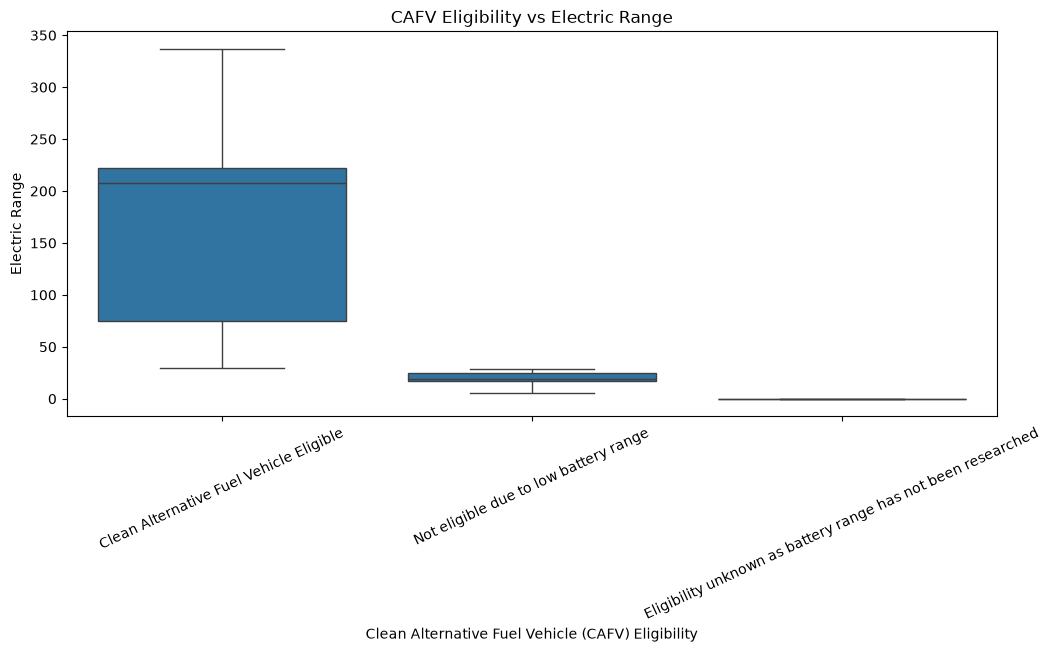

In [36]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df,x='Clean Alternative Fuel Vehicle (CAFV) Eligibility',y='Electric Range')
plt.xticks(rotation=25)
plt.title('CAFV Eligibility vs Electric Range')
plt.show()

#### Vehicles classified as Clean Alternative Fuel Vehicle eligible generally exhibit much higher electric ranges than those deemed ineligible due to low battery range. This indicates that electric driving range is a key factor influencing CAFV eligibility status.

### Graph 5: Make vs Electric Range

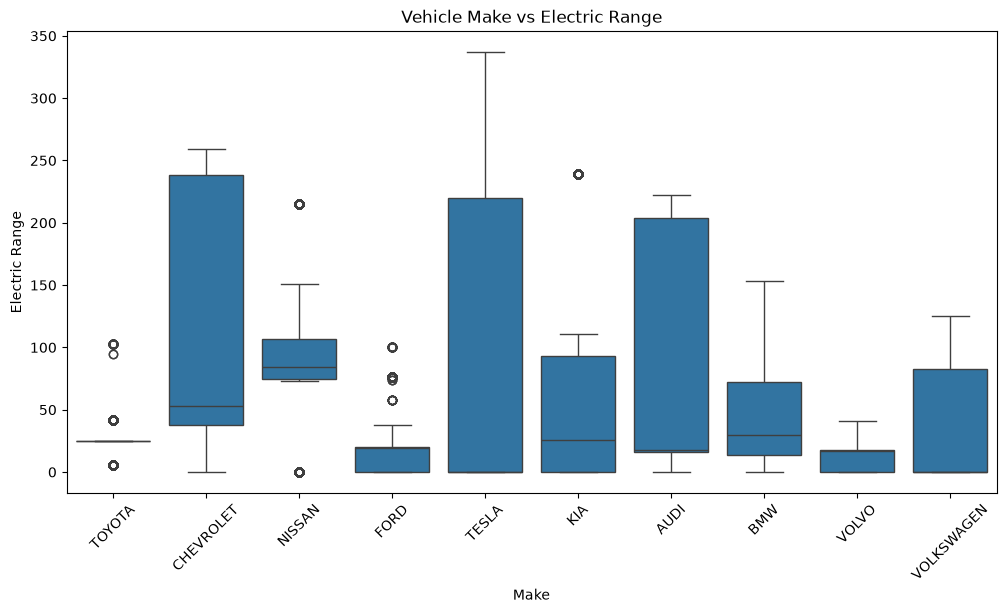

In [37]:
top10 = df['Make'].value_counts().head(10).index
filtered = df[df['Make'].isin(top10)]
plt.figure(figsize=(12,6))
sns.boxplot(data=filtered,x='Make',y='Electric Range')
plt.xticks(rotation=45)
plt.title('Vehicle Make vs Electric Range')
plt.show()

#### Electric range varies considerably across manufacturers with Tesla and Audi generally exhibiting higher maximum ranges than most other brands. Manufacturers such as Ford, Toyota, and Volvo tend to have lower median electric ranges reflecting differences in vehicle technologies and market segments.

### Graph 6: Make vs EV Type

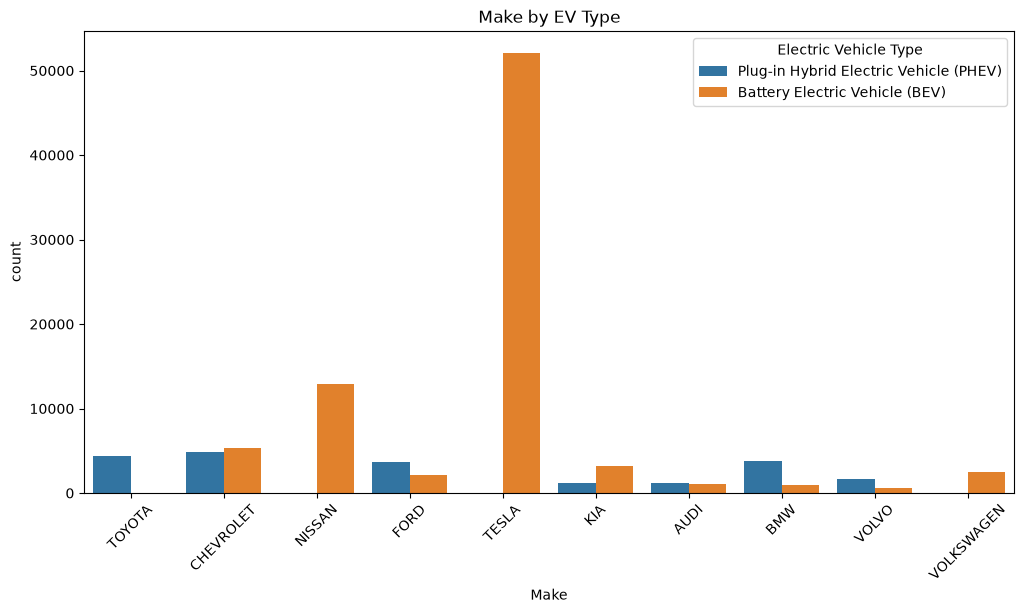

In [38]:
top10 = df['Make'].value_counts().head(10).index
filtered = df[df['Make'].isin(top10)]
plt.figure(figsize=(12,6))
sns.countplot(data=filtered,x='Make',hue='Electric Vehicle Type')
plt.xticks(rotation=45)
plt.title('Make by EV Type')
plt.show()

#### Tesla's registrations are almost entirely Battery Electric Vehicles (BEVs) whereas manufacturers such as Toyota, Ford, BMW, and Volvo have a larger share of Plug-in Hybrid Electric Vehicles (PHEVs). This highlights differing manufacturer strategies in the electric vehicle market.

## 4. Multivariate Analysis

### Graph 1: Correlation Heatmap

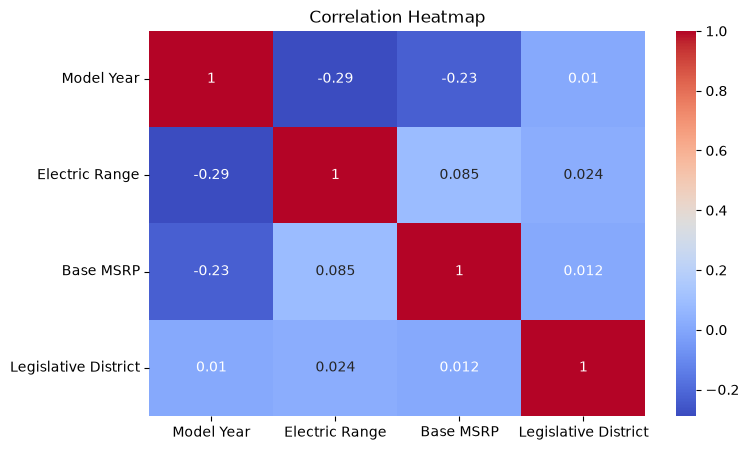

In [39]:
num_cols = ['Model Year','Electric Range','Base MSRP','Legislative District']
plt.figure(figsize=(8,5))
sns.heatmap(df[num_cols].corr(),annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Most numerical variables exhibit weak correlations suggesting limited linear relationships within the dataset. Model Year shows a slight negative correlation with Electric Range(-0.29), while Legislative District appears largely unrelated to the other variables with correlations close to zero.

### Graph 2: Electric Range vs MSRP by EV Type

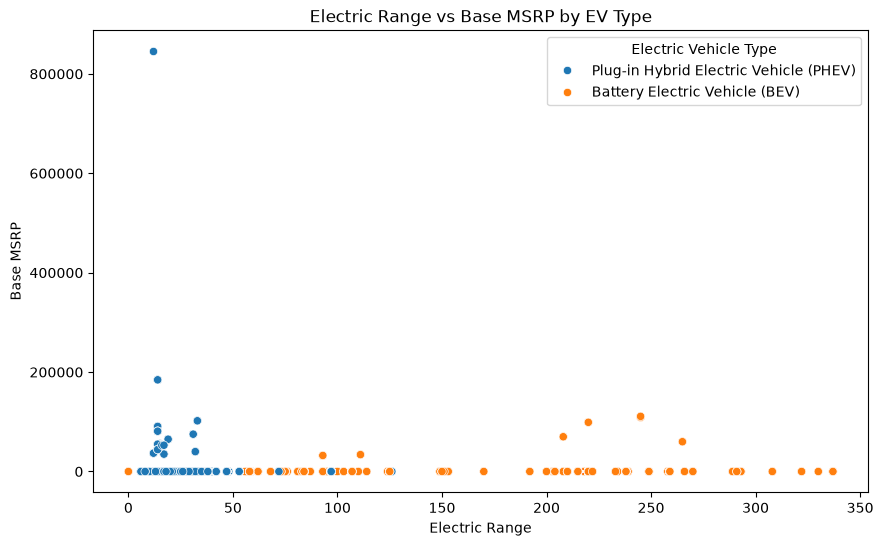

In [40]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='Electric Range',y='Base MSRP',hue='Electric Vehicle Type')
plt.title('Electric Range vs Base MSRP by EV Type')
plt.show()

#### Most vehicles have a Base MSRP of zero regardless of electric range indicating limited variation in the MSRP data. A small number of vehicles exhibit exceptionally high MSRP values but no clear relationship between price and electric range can be observed due to the large proportion of zero values.

### Graph 3: Model Year vs Electric Range by Make

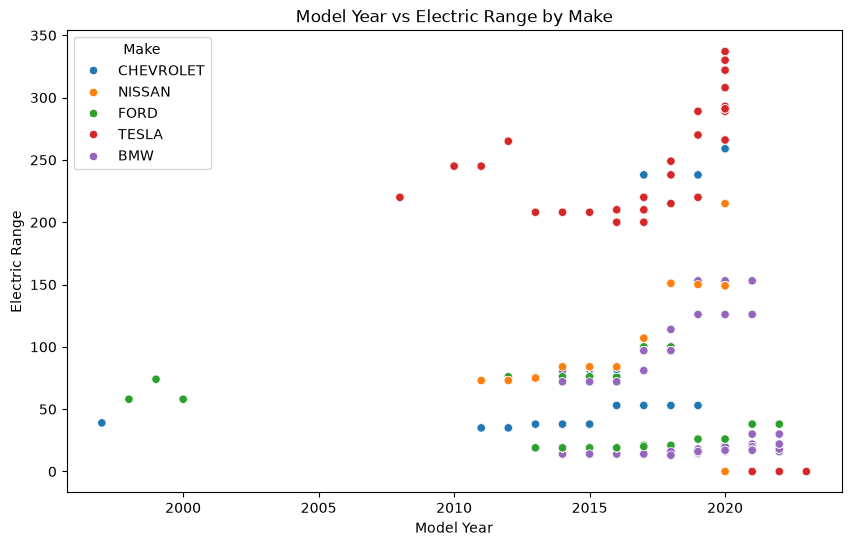

In [41]:
top5 = df['Make'].value_counts().head(5).index
filtered = df[df['Make'].isin(top5)]
plt.figure(figsize=(10,6))
sns.scatterplot(data=filtered,x='Model Year',y='Electric Range',hue='Make')
plt.title('Model Year vs Electric Range by Make')
plt.show()

#### Tesla vehicles consistently demonstrate the highest electric ranges across model years while other manufacturers generally offer lower ranges. There is an overall trend of increasing electric range in newer model years reflecting technological improvements across manufacturers.

### Graph 4: Electric Range by Make and EV Type

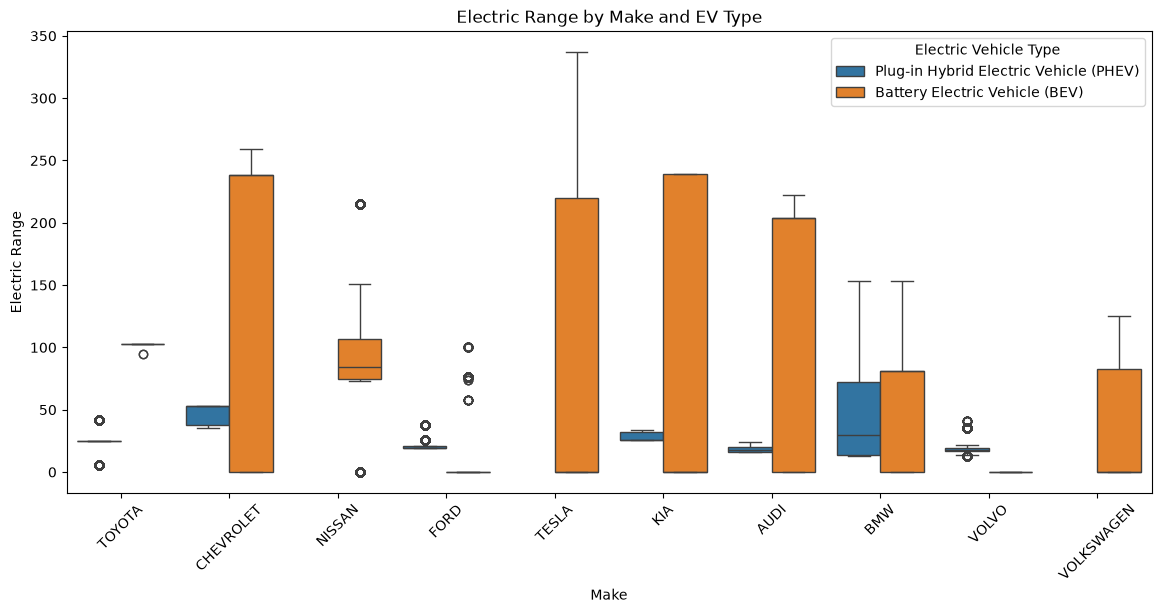

In [42]:
top10 = df['Make'].value_counts().head(10).index
filtered = df[df['Make'].isin(top10)]
plt.figure(figsize=(14,6))
sns.boxplot(data=filtered,x='Make',y='Electric Range',hue='Electric Vehicle Type')
plt.xticks(rotation=45)
plt.title('Electric Range by Make and EV Type')
plt.show()

#### Battery Electric Vehicles (BEVs) generally achieve higher electric ranges than Plug-in Hybrid Electric Vehicles (PHEVs) across most manufacturers. The variation in range also differs by make indicating that manufacturers adopt different battery capacities and EV technologies in their vehicle portfolios.

### Graph 5: County × EV Type Heatmap

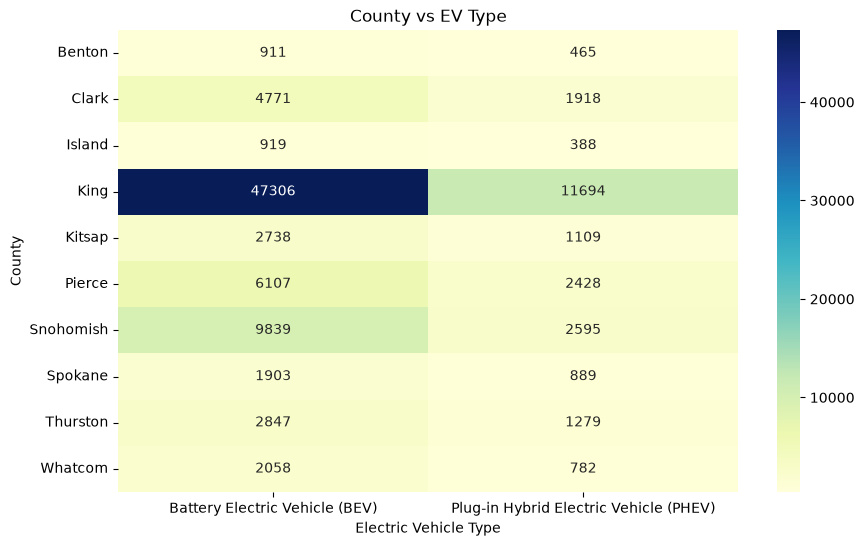

In [43]:
top10_counties = df['County'].value_counts().head(10).index
filtered = df[df['County'].isin(top10_counties)]
cross_tab = pd.crosstab(filtered['County'],filtered['Electric Vehicle Type'])
plt.figure(figsize=(10,6))
sns.heatmap(cross_tab,annot=True,fmt='d',cmap='YlGnBu')
plt.title('County vs EV Type')
plt.show()

#### Battery Electric Vehicles (BEVs) outnumber Plug-in Hybrid Electric Vehicles (PHEVs) across all counties indicating a stronger preference for fully electric vehicles. King County exhibits the highest concentration of both EV types by a substantial margin highlighting its leading role in EV adoption compared to other counties.

# Key Findings

- The dataset includes 112,634 electric vehicle records and 17 variables covering vehicle features, geographic location, and eligibility.
- Battery Electric Vehicles (BEVs) make up most of the dataset with 86,044 vehicles, whereas Plug-in Hybrid Electric Vehicles (PHEVs) cover 26,590 vehicles. Therefore, BEVs reflect greater adoption of fully electric vehicles.
- Electric vehicle registrations are concentrated in more recent model years especially from 2018 through 2023. This indicates a rapid rise in EV adoption in recent years.
- Tesla is the most frequently represented manufacturer in the dataset accounting for a significant share of registered electric vehicles.
- King County has the highest number of EV registrations, well above every other county, underscoring regional variation in EV adoption.
- Battery Electric Vehicles typically provide substantially greater electric ranges than Plug-in Hybrid Electric Vehicles. This reflects differences in vehicle technology and battery capacity.
- Electric range differs by manufacturer, with Tesla and several others showing higher average ranges than many competing brands.
- Outlier analysis found vehicles with exceptionally long electric ranges. These values appear to reflect genuine vehicle characteristics rather than data-entry errors, so they were retained.
- Base MSRP was explored as a pricing variable and it was observed that approximately 97% of observations contained a value of zero.

# Conclusion

#### This exploratory data analysis investigated patterns and trends in the Electric Vehicle Population dataset. The analysis revealed that electric vehicle adoption has grown substantially in recent years with Battery Electric Vehicles (BEVs) becoming the predominant vehicle type. Tesla ranked as the top manufacturer by vehicle registrations, while King County had the greatest concentration of electric vehicles. The findings also showed that electric range varies considerably by vehicle type and manufacturer, with BEVs generally offering greater range than PHEVs. Overall, the results highlight the growing adoption of electric mobility and offer valuable insights into vehicle distribution, geographic patterns, and electric vehicle performance.